In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib joblib

In [2]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
df = pd.read_excel(
    "merged_fb_tiktok.xlsx",
    sheet_name="MERGED_DATA"
)
print("Kích thước dữ liệu:", df.shape)
display(df.head())

Saving merged_fb_tiktok.xlsx to merged_fb_tiktok.xlsx
Kích thước dữ liệu: (3314, 8)


,Comment ID,Source,Original ID,RAW Text,Clean Text,Text_PhoBERT,Text_TFIDF,Final Label
0,1,Facebook,2,Anh già r mà anh vẫn đỉnh voãi\n🤣,anh già rồi anh vẫn đỉnh rất,NaN,NaN,Positive
1,2,Facebook,3,Nhữ Thị Thảo anh zai đóng phản diện là chuẩn c...,anh_trai đóng phản_diện chuẩn luôn_luôn,NaN,NaN,Positive
2,3,Facebook,4,Nhữ Thị Thảo 1 mình a 3 em trong phim mà lại 🤣🤣,mình anh_em trong phim mà_lại,NaN,NaN,Neutral
3,4,Facebook,9,Nhữ Thị Thảo anh Ngoan ở bên Thiên đường máu l...,anh ngoan bên thiên đường_máu làm trùm rồi qua...,NaN,NaN,Neutral
4,5,Facebook,10,Cậu Cả chén bà bầu + 1 bà bếp ngồi ôm gối thôi mà,chén bà bầu bà bếp ngồi ôm gối thôi,NaN,NaN,Neutral


In [3]:
data = df[["Clean Text", "Final Label"]].copy()

data = data.rename(columns={
    "Clean Text": "text",
    "Final Label": "label"
})

print("Kích thước dữ liệu:", data.shape)
display(data.head())


Kích thước dữ liệu: (3314, 2)


,text,label
0,anh già rồi anh vẫn đỉnh rất,Positive
1,anh_trai đóng phản_diện chuẩn luôn_luôn,Positive
2,mình anh_em trong phim mà_lại,Neutral
3,anh ngoan bên thiên đường_máu làm trùm rồi qua...,Neutral
4,chén bà bầu bà bếp ngồi ôm gối thôi,Neutral


In [4]:
label_counts = data["label"].value_counts()

label_percent = data["label"].value_counts(normalize=True) * 100

label_stats = pd.DataFrame({
    "Số lượng": label_counts,
    "Tỷ lệ (%)": label_percent.round(2)
})

display(label_stats)

,Số lượng,Tỷ lệ (%)
label,,
Positive,2062,62.22
Neutral,692,20.88
Negative,560,16.90


In [5]:
from sklearn.model_selection import train_test_split

X = data["text"]
y = data["label"]

X_train , X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y,
    random_state=18
)

print("Số mẫu Train:", len(X_train))
print("Số mẫu Test:", len(X_test))

print("\nPhân bố nhãn Train:")
print(y_train.value_counts())

print("\nPhân bố nhãn Test:")
print(y_test.value_counts())

Số mẫu Train: 2651
Số mẫu Test: 663

Phân bố nhãn Train:
label
Positive    1649
Neutral      554
Negative     448
Name: count, dtype: int64

Phân bố nhãn Test:
label
Positive    413
Neutral     138
Negative    112
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=18
)

tfidf_ovr = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("svm", LinearSVC(
        C=1.0,
        class_weight=None,
        loss="squared_hinge",
        random_state=18
    ))
])

scores_tfidf_ovr = cross_val_score(
    tfidf_ovr,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Macro F1 từng fold:", scores_tfidf_ovr.round(4))
print("Macro F1 trung bình:", round(scores_tfidf_ovr.mean(), 4))

Macro F1 từng fold: [0.6138 0.6048 0.5363 0.6114 0.6189]
Macro F1 trung bình: 0.5971


In [7]:
#OvO
from sklearn.multiclass import OneVsOneClassifier

tfidf_ovo = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("svm", OneVsOneClassifier(
        LinearSVC(
            C=1.0,
            class_weight=None,
            loss="squared_hinge",
            random_state=18
        )
    ))
])

scores_tfidf_ovo = cross_val_score(
    tfidf_ovo,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Macro F1 từng fold:", scores_tfidf_ovo.round(4))
print("Macro F1 trung bình:", round(scores_tfidf_ovo.mean(), 4))

Macro F1 từng fold: [0.6016 0.599  0.5307 0.5959 0.6133]
Macro F1 trung bình: 0.5881


### Tối ưu OvR

In [8]:
from sklearn.model_selection import GridSearchCV

param_grid_tfidf_ovr = {
    "svm__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "svm__class_weight": [None, "balanced"],
    "svm__loss": ["hinge", "squared_hinge"],
    "svm__dual": [True]
}

grid_tfidf_ovr = GridSearchCV(
    estimator=tfidf_ovr,
    param_grid=param_grid_tfidf_ovr,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_tfidf_ovr.fit(X_train, y_train)

print("Tham số tốt nhất (OvR):")
print(grid_tfidf_ovr.best_params_)

print("\nMacro F1 CV tốt nhất:")
print(round(grid_tfidf_ovr.best_score_, 4))

Tham số tốt nhất (OvR):
{'svm__C': 1, 'svm__class_weight': 'balanced', 'svm__dual': True, 'svm__loss': 'hinge'}

Macro F1 CV tốt nhất:
0.6327


In [9]:
#Tối ưu đặc trưng Tfidf
param_grid_features_ovr = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__min_df": [1, 2, 3],
    "tfidf__sublinear_tf": [False, True]
}

grid_features_ovr = GridSearchCV(
    estimator=grid_tfidf_ovr.best_estimator_,
    param_grid=param_grid_features_ovr,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_features_ovr.fit(X_train, y_train)

print("Tham số TF-IDF tốt nhất (OvR):")
print(grid_features_ovr.best_params_)

print("\nMacro F1 CV tốt nhất (OvR):")
print(round(grid_features_ovr.best_score_, 4))


Tham số TF-IDF tốt nhất (OvR):
{'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': False}

Macro F1 CV tốt nhất (OvR):
0.6327


### Tối ưu OvO

In [10]:
param_grid_tfidf_ovo = {
    "svm__estimator__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "svm__estimator__class_weight": [None, "balanced"],
    "svm__estimator__loss": ["hinge", "squared_hinge"],
    "svm__estimator__dual": [True]
}

grid_tfidf_ovo = GridSearchCV(
    estimator=tfidf_ovo,
    param_grid=param_grid_tfidf_ovo,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_tfidf_ovo.fit(X_train, y_train)

print("Tham số tốt nhất (OvO):")
print(grid_tfidf_ovo.best_params_)

print("\nMacro F1 CV tốt nhất (OvO):")
print(round(grid_tfidf_ovo.best_score_, 4))


Tham số tốt nhất (OvO):
{'svm__estimator__C': 0.3, 'svm__estimator__class_weight': 'balanced', 'svm__estimator__dual': True, 'svm__estimator__loss': 'squared_hinge'}

Macro F1 CV tốt nhất (OvO):
0.6369


In [11]:
#Tối ưu tfidf ovo
param_grid_features_ovo = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__min_df": [1, 2, 3],
    "tfidf__sublinear_tf": [False, True]
}

grid_features_ovo = GridSearchCV(
    estimator=grid_tfidf_ovo.best_estimator_,
    param_grid=param_grid_features_ovo,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_features_ovo.fit(X_train, y_train)

print("Tham số TF-IDF tốt nhất (OvO):")
print(grid_features_ovo.best_params_)

print("\nMacro F1 CV tốt nhất (OvO):")
print(round(grid_features_ovo.best_score_, 4))


Tham số TF-IDF tốt nhất (OvO):
{'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 3), 'tfidf__sublinear_tf': True}

Macro F1 CV tốt nhất (OvO):
0.6375



### Sử dụng RBF

In [12]:

from sklearn.svm import SVC

tfidf_rbf = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=None,
        random_state=18
    ))
])

scores_tfidf_rbf = cross_val_score(
    tfidf_rbf,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Macro F1 từng fold:", scores_tfidf_rbf.round(4))
print("Macro F1 trung bình:", round(scores_tfidf_rbf.mean(), 4))

Macro F1 từng fold: [0.3928 0.3761 0.3614 0.365  0.3746]
Macro F1 trung bình: 0.374


In [13]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred_rbf_oof = cross_val_predict(
    tfidf_rbf,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

print("Phân bố nhãn dự đoán:")
print(pd.Series(y_pred_rbf_oof).value_counts())

print("\nClassification Report:")
print(classification_report(
    y_train,
    y_pred_rbf_oof,
    digits=4,
    zero_division=0
))


Phân bố nhãn dự đoán:
Positive    2535
Neutral       91
Negative      25
Name: count, dtype: int64

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8000    0.0446    0.0846       448
     Neutral     0.9011    0.1480    0.2543       554
    Positive     0.6473    0.9951    0.7844      1649

    accuracy                         0.6575      2651
   macro avg     0.7828    0.3959    0.3744      2651
weighted avg     0.7262    0.6575    0.5554      2651



In [14]:
#tối ưu
from sklearn.model_selection import GridSearchCV

param_grid_rbf = {
    "svm__C": [1, 10, 100],
    "svm__gamma": [0.001, 0.003, 0.01, 0.1, "scale"],
    "svm__class_weight": [None, "balanced"]
}

grid_rbf = GridSearchCV(
    estimator=tfidf_rbf,
    param_grid=param_grid_rbf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_rbf.fit(X_train, y_train)

print("Tham số tốt nhất RBF:")
print(grid_rbf.best_params_)

print("\nMacro F1 CV tốt nhất:")
print(round(grid_rbf.best_score_, 4))


Tham số tốt nhất RBF:
{'svm__C': 100, 'svm__class_weight': 'balanced', 'svm__gamma': 0.003}

Macro F1 CV tốt nhất:
0.6337


In [15]:
param_grid_features_rbf = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__min_df": [1, 2, 3],
    "tfidf__sublinear_tf": [False, True]
}

grid_features_rbf = GridSearchCV(
    estimator=grid_rbf.best_estimator_,
    param_grid=param_grid_features_rbf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_features_rbf.fit(X_train, y_train)

print("Tham số TF-IDF tốt nhất (RBF):")
print(grid_features_rbf.best_params_)

print("\nMacro F1 CV tốt nhất (RBF):")
print(round(grid_features_rbf.best_score_, 4))

Tham số TF-IDF tốt nhất (RBF):
{'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': False}

Macro F1 CV tốt nhất (RBF):
0.6337



### 16. Lựa chọn mô hình TF-IDF + SVM tốt nhất

Sau tối ưu, Linear SVM (OvO) đạt Macro F1 CV = **0.6375**, cao hơn OvR (0.6327) và RBF (0.6337).
Nhóm chọn **TF-IDF + Linear SVM (OvO)** làm mô hình tốt nhất.
Cấu hình: `C=0.3`, `class_weight='balanced'`, `loss='squared_hinge'`, `ngram_range=(1,3)`, `min_df=2`, `sublinear_tf=True`.

In [16]:

best_tfidf_svm = grid_features_ovo.best_estimator_

tfidf = best_tfidf_svm.named_steps["tfidf"]
svm = best_tfidf_svm.named_steps["svm"]

features = tfidf.get_feature_names_out()

pairs = [
    ("Negative", "Neutral"),
    ("Negative", "Positive"),
    ("Neutral", "Positive")
]

for k in range(3):

    weights = svm.estimators_[k].coef_[0]
    sorted_idx = weights.argsort()

    label_a, label_b = pairs[k]

    print(f"\n===== {label_a} vs {label_b} =====")

    print(f"\n10 đặc trưng ủng hộ {label_a}:")
    for i in sorted_idx[:10]:
        print(features[i], ":", round(weights[i], 4))

    print(f"\n10 đặc trưng ủng hộ {label_b}:")
    for i in sorted_idx[-10:][::-1]:
        print(features[i], ":", round(weights[i], 4))



===== Negative vs Neutral =====

10 đặc trưng ủng hộ Negative:
điểm : -1.1289
nó : -0.9518
rất : -0.9288
dở : -0.9156
xàm : -0.89
tuyên_truyền : -0.814
cứ : -0.7994
làm : -0.7652
thua : -0.7563
quá : -0.7491

10 đặc trưng ủng hộ Neutral:
có : 1.313
khác : 0.7916
sẽ : 0.7818
bạn : 0.7678
hay không : 0.7293
tuổi : 0.7243
người : 0.7155
anh : 0.6747
em : 0.6612
mới : 0.6306

===== Negative vs Positive =====

10 đặc trưng ủng hộ Negative:
bình_thường : -1.3191
không : -1.2087
dở : -1.1664
không hay : -1.1644
kết : -1.0972
thua : -1.0887
tuyên_truyền : -1.0863
xàm : -1.0605
kiểu : -1.0533
điểm : -1.0413

10 đặc trưng ủng hộ Positive:
hay : 2.0035
đỉnh : 1.067
xem : 1.0628
tốt : 0.9696
đã : 0.9598
cuốn : 0.939
phim hay : 0.9163
đáng : 0.8718
muốn : 0.8642
lần : 0.761

===== Neutral vs Positive =====

10 đặc trưng ủng hộ Neutral:
không : -1.232
hay không : -1.1559
tuổi : -1.0267
không_b : -1.0078
có : -0.9725
không_ạ : -0.9311
chiếu : -0.9236
xem được : -0.9004
sao : -0.8668
trải_nghiệm : -0

In [17]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

best_tfidf_svm = grid_features_ovo.best_estimator_

y_pred_tfidf = best_tfidf_svm.predict(X_test)

accuracy_tfidf = accuracy_score(y_test, y_pred_tfidf)
precision_tfidf = precision_score(y_test, y_pred_tfidf, average="macro")
recall_tfidf = recall_score(y_test, y_pred_tfidf, average="macro")
macro_f1_tfidf = f1_score(y_test, y_pred_tfidf, average="macro")
weighted_f1_tfidf = f1_score(y_test, y_pred_tfidf, average="weighted")

print("===== TF-IDF + SVM (OvO) - TEST =====")
print("Accuracy:", round(accuracy_tfidf, 4))
print("Macro Precision:", round(precision_tfidf, 4))
print("Macro Recall:", round(recall_tfidf, 4))
print("Macro F1:", round(macro_f1_tfidf, 4))
print("Weighted F1:", round(weighted_f1_tfidf, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tfidf, digits=4))


===== TF-IDF + SVM (OvO) - TEST =====
Accuracy: 0.724
Macro Precision: 0.6505
Macro Recall: 0.675
Macro F1: 0.6596
Weighted F1: 0.729

Classification Report:
              precision    recall  f1-score   support

    Negative     0.5211    0.6607    0.5827       112
     Neutral     0.5809    0.5725    0.5766       138
    Positive     0.8494    0.7918    0.8195       413

    accuracy                         0.7240       663
   macro avg     0.6505    0.6750    0.6596       663
weighted avg     0.7380    0.7240    0.7290       663



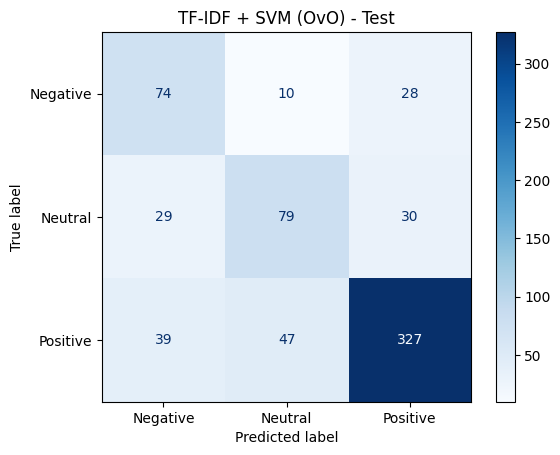

In [18]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["Negative", "Neutral", "Positive"]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tfidf,
    labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF + SVM (OvO) - Test")
plt.show()


In [19]:

import joblib
from google.colab import files

joblib.dump(best_tfidf_svm, "best_tfidf_svm_v2.joblib")

files.download("best_tfidf_svm_v2.joblib")

print("Đã lưu")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Đã lưu
